In [ ]:
!pip install pyspark

In [ ]:
import numpy as np
import time

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.types import StructType, StructField, IntegerType, ArrayType, FloatType

spark = SparkSession.builder.appName("LSH Distance Join").config("spark.driver.memory", "8g").config("spark.executor.memory", "8g").getOrCreate()

In [ ]:
!wget ftp://ftp.irisa.fr/local/texmex/corpus/sift.tar.gz
!tar -xzf sift.tar.gz

--2026-06-12 07:33:34--  ftp://ftp.irisa.fr/local/texmex/corpus/sift.tar.gz
           => ‘sift.tar.gz’
Resolving ftp.irisa.fr (ftp.irisa.fr)... 131.254.254.45, 2001:660:7303:254::45
Connecting to ftp.irisa.fr (ftp.irisa.fr)|131.254.254.45|:21... connected.
Logging in as anonymous ... Logged in!
==> SYST ... done.    ==> PWD ... done.
==> TYPE I ... done.  ==> CWD (1) /local/texmex/corpus ... done.
==> SIZE sift.tar.gz ... 168280445
==> PASV ... done.    ==> RETR sift.tar.gz ... done.
Length: 168280445 (160M) (unauthoritative)

sift.tar.gz         100%[===================>] 160.48M  31.0MB/s    in 6.0s    

2026-06-12 07:33:42 (26.6 MB/s) - ‘sift.tar.gz’ saved [168280445]



In [ ]:
def read_fvecs(filename):
    with open(filename, 'rb') as f:
        data = np.fromfile(f, dtype=np.float32)
    dim = data[0].view(np.int32)
    return data.reshape(-1, dim + 1)[:, 1:]

base_vectors = read_fvecs('sift/sift_base.fvecs')
print(f"Shape: {base_vectors.shape}")

Shape: (1000000, 128)


Ορισμός υποσυνόλων

In [ ]:
R = base_vectors[:2000]   # first 2000
S = base_vectors[2000:4000]  # next 2000

Τα 2 σύνολα διανυσμάτων R,S μετατρέπονται σε Spark Dataframes.

Με την εντολή schema γίνεται ο ορισμός της δομής του DF.

In [ ]:
schema = StructType([
    StructField("id", IntegerType(), False),
    StructField("vector", ArrayType(FloatType()), False)
])

R_data = [(i, r.tolist()) for i, r in enumerate(R)]
S_data = [(i, s.tolist()) for i, s in enumerate(S)]

df_R = spark.createDataFrame(R_data, schema=schema)
df_S = spark.createDataFrame(S_data, schema=schema)

df_R.show(3)

+---+--------------------+
| id|              vector|
+---+--------------------+
|  0|[0.0, 16.0, 35.0,...|
|  1|[14.0, 35.0, 19.0...|
|  2|[0.0, 1.0, 5.0, 3...|
+---+--------------------+
only showing top 3 rows


In [ ]:
df_S.show(3)

+---+--------------------+
| id|              vector|
+---+--------------------+
|  0|[1.0, 0.0, 0.0, 1...|
|  1|[33.0, 0.0, 0.0, ...|
|  2|[0.0, 0.0, 1.0, 2...|
+---+--------------------+
only showing top 3 rows


Ορισμός των παραμέτρων για τον LSH.

Δημιουργία πινάκων.

In [ ]:
L = 15  # αριθμός hash tables
k = 4  # hash functions ανά table
w = 600  # πλάτος bucket
dim = 128  # διαστάσεις SIFT1M
theta = 300

np.random.seed(42)

a = np.random.randn(L, k, dim).astype(np.float32)
b = np.random.uniform(0, w, (L, k)).astype(np.float32)

In [ ]:
a_broadcast = spark.sparkContext.broadcast(a)
b_broadcast = spark.sparkContext.broadcast(b)

In [ ]:
from pyspark.sql.functions import udf
from pyspark.sql.types import ArrayType, StringType

Συνάρτηση υπολογισμού bucket για διανύσματα.

Είσοδος: διάνυσμα



In [ ]:
def hash_vector(vector):
 hash_keys = []
 bucket = []
 x=np.array(vector)

 start = time.time()
 for l in range(L):
  a = a_broadcast.value[l]
  b = b_broadcast.value[l]
  bucket = []
  for j in range(k):
   hash = np.floor((np.dot(a[j], x) + b[j]) / w)
   hash = str(int(hash))
   bucket.append(hash)
  hash_keys.append(",".join(bucket))
 return hash_keys

hash_udf = udf(hash_vector, ArrayType(StringType()))




εως τωρα:

Βήμα 1: Φόρτωση δεδομένων
Διαβάζουμε το SIFT1M dataset από το binary format .fvecs και το μετατρέπουμε σε numpy array. Παίρνουμε 10.000 διανύσματα για R και 10.000 για S.

Βήμα 2: Δημιουργία Spark DataFrames
Μετατρέπουμε τα numpy arrays σε Spark DataFrames με δύο στήλες — ένα id για να αναγνωρίζουμε κάθε διάνυσμα και το vector με τις 128 τιμές του.

Βήμα 3: Δημιουργία Hash Functions
Δημιουργούμε τυχαία τα a και b με NumPy — αυτά είναι οι παράμετροι των hash functions. Τα κάνουμε broadcast ώστε το Spark να τα στείλει μία φορά σε όλους τους workers.

Βήμα 4: Υπολογισμός Hash Keys (UDF)
Ορίζουμε μια συνάρτηση hash_vector που για κάθε διάνυσμα:

Για κάθε από τα L tables, εφαρμόζει k hash functions με τη φόρμουλα floor((a·x + b) / w)
Συνενώνει τα k αποτελέσματα σε ένα string π.χ. "3,7,2,5" — αυτό είναι το hash key του table
Επιστρέφει L hash keys — ένα για κάθε table

Αυτή η συνάρτηση γίνεται UDF και εφαρμόζεται παράλληλα σε κάθε γραμμή του DataFrame.

Που πάμε μετά

Εφαρμογή της UDF στα df_R και df_S
Μετατροπή σε format (id, table_id, hash_key)
Join μεταξύ R και S με κλειδί (table_id, hash_key)
Distinct για αφαίρεση duplicates
Verification της πραγματικής απόστασης

In [ ]:
from pyspark.sql.functions import col

In [ ]:
lsh_start = time.time()

# Corrected UDF application
df_R_hashed = df_R.withColumn("hashed_vectors", hash_udf(col("vector")))
df_S_hashed = df_S.withColumn("hashed_vectors", hash_udf(col("vector")))


In [ ]:
from pyspark.sql.functions import posexplode

In [ ]:
df_R_exploded = df_R_hashed.select(
    "id",
    posexplode("hashed_vectors").alias("table_id", "hash_key")
)

In [ ]:
df_S_exploded = df_S_hashed.select(
    "id",
    posexplode("hashed_vectors").alias("table_id", "hash_key")
)

candidates = df_R_exploded.join(
    df_S_exploded,
    on=["table_id", "hash_key"],
    how="inner"
).select(
    df_R_exploded["id"].alias("r_id"),
    df_S_exploded["id"].alias("s_id")
)

candidates_distinct = candidates.distinct()


In [ ]:

cand = candidates.count()
cand_dist = candidates_distinct.count()

print(f"Candidates before distinct: {cand}")
print(f"Candidates after distinct: {cand_dist}")

Candidates before distinct: 2029125
Candidates after distinct: 1430309


In [ ]:
#διανύσματα του R
candidates_with_vectors = candidates_distinct \
    .join(df_R.select(
        col("id").alias("r_id"),
        col("vector").alias("r_vector")),
    on="r_id") \
    .join(df_S.select(
        col("id").alias("s_id"),
        col("vector").alias("s_vector")),
    on="s_id")



In [ ]:
def euclideian_distance(vector1, vector2):
    return float(np.linalg.norm(np.array(vector1) - np.array(vector2)))

ed_udf = udf(euclideian_distance, FloatType())


In [ ]:
ed = ed_udf(col("r_vector"), col("s_vector"))

candidates_with_distance = candidates_with_vectors.withColumn(
    "distance",
    ed
)

In [ ]:
results = candidates_with_distance.filter(col("distance") < theta)
number = results.count()

lsh_time = time.time() - lsh_start

print(f"Number of results: {number}")
results.show(5)

Number of results: 23235
+----+----+--------------------+--------------------+---------+
|s_id|r_id|            r_vector|            s_vector| distance|
+----+----+--------------------+--------------------+---------+
|1248| 129|[3.0, 2.0, 11.0, ...|[18.0, 4.0, 0.0, ...| 289.0519|
| 940|  58|[16.0, 2.0, 8.0, ...|[26.0, 4.0, 2.0, ...|268.34494|
|1789| 616|[58.0, 7.0, 7.0, ...|[22.0, 0.0, 2.0, ...|  295.266|
| 653| 879|[27.0, 5.0, 8.0, ...|[1.0, 1.0, 21.0, ...|292.03937|
| 979| 550|[5.0, 1.0, 1.0, 8...|[23.0, 97.0, 60.0...|294.40448|
+----+----+--------------------+--------------------+---------+
only showing top 5 rows


brute force για check και recall

In [ ]:
# Cross join - baseline (στο μικρό υποσύνολο)

df_R_base = df_R.select(
    col("id").alias("r_id"),
    col("vector").alias("r_vector")
)

df_S_base = df_S.select(
    col("id").alias("s_id"),
    col("vector").alias("s_vector")
)

start = time.time()

baseline = df_R_base.join(df_S_base).withColumn(
    "distance",
    ed_udf(col("r_vector"), col("s_vector"))
).filter(col("distance") < theta)

ground_truth_count = baseline.count()

end = time.time()
baseline_time = end - start


In [ ]:
# ζεύγη LSH για set
lsh_pairs = set(
    results.select("r_id", "s_id")
    .rdd.map(lambda row: (row.r_id, row.s_id))
    .collect()
)

# ζεύγη baseline για set
gt_pairs = set(
    baseline.select("r_id", "s_id")
    .rdd.map(lambda row: (row.r_id, row.s_id))
    .collect()
)

# Υπολογισμός recall
common = len(lsh_pairs & gt_pairs)
recall = common / len(gt_pairs)

In [ ]:
with open(f"results_k{k}_L{L}_w{w}_{theta}.txt", "w") as results_txt:
    results_txt.write("=" * 50 + "\n")
    results_txt.write("     LSH DISTANCE JOIN - ΑΠΟΤΕΛΕΣΜΑΤΑ\n")
    results_txt.write("=" * 50 + "\n")

    results_txt.write("\n ΠΑΡΑΜΕΤΡΟΙ\n")
    results_txt.write(f"  Dataset R:        {len(R)} διανύσματα\n")
    results_txt.write(f"  Dataset S:        {len(S)} διανύσματα\n")
    results_txt.write(f"  Διαστάσεις:       {dim}\n")
    results_txt.write(f"  Θ:                {theta}\n")
    results_txt.write(f"  L (hash tables):  {L}\n")
    results_txt.write(f"  k (hash funcs):   {k}\n")
    results_txt.write(f"  w (bucket width): {w}\n")

    results_txt.write("\n ΑΠΟΤΕΛΕΣΜΑΤΑ LSH\n")
    results_txt.write(f"  Candidates προ distinct:  {cand}\n")
    results_txt.write(f"  Candidates μετά distinct:  {cand_dist}\n")
    results_txt.write(f"  Τελικά αποτελέσματα:       {number}\n")
    results_txt.write(f"  Χρόνος εκτέλεσης LSH:      {lsh_time:.2f} δευτερόλεπτα\n")

    results_txt.write("\n ΑΠΟΤΕΛΕΣΜΑΤΑ BASELINE\n")
    results_txt.write(f"  Ground truth ζεύγη:     {ground_truth_count}\n")
    results_txt.write(f"  Χρόνος εκτέλεσης baseline: {baseline_time:.2f} δευτερόλεπτα\n")

    results_txt.write("\n ΑΞΙΟΛΟΓΗΣΗ\n")
    results_txt.write(f"  Κοινά ζεύγη:    {common}\n")
    results_txt.write(f"  Recall:            {recall:.2%}\n")
    results_txt.write(f"  Ταχύτητα:        {baseline_time/lsh_time:.1f}πιο γρήγορο.\n")

    results_txt.write("=" * 50 + "\n")
    results_txt.write("\n")
    results_txt.write("=" * 50 + "\n")

In [ ]:

print("     LSH DISTANCE JOIN - ΑΠΟΤΕΛΕΣΜΑΤΑ")
print("\n ΠΑΡΑΜΕΤΡΟΙ")
print(f"  Dataset R:        {len(R)} διανύσματα")
print(f"  Dataset S:        {len(S)} διανύσματα")
print(f"  Διαστάσεις:       {dim}")
print(f"  Θ:                {theta}")
print(f"  L (hash tables):  {L}")
print(f"  k (hash funcs):   {k}")
print(f"  w (bucket width): {w}")

print("\n ΑΠΟΤΕΛΕΣΜΑΤΑ LSH")
print(f"  Candidates προ distinct:   {cand}")
print(f"  Candidates μετά distinct:  {cand_dist}")
print(f"  Τελικά αποτελέσματα:       {number}")
print(f"  Χρόνος εκτέλεσης LSH:      {lsh_time:.2f} δευτερόλεπτα")

print("\n ΑΠΟΤΕΛΕΣΜΑΤΑ BASELINE")
print(f"  Ground truth ζεύγη:        {ground_truth_count}")
print(f"  Χρόνος εκτέλεσης baseline: {baseline_time:.2f} δευτερόλεπτα")

print("\n ΑΞΙΟΛΟΓΗΣΗ")
print(f"  Κοινά ζεύγη:       {common}")
print(f"  Recall:            {recall:.2%}")
print(f"  Επιτάχυνση:        {baseline_time/lsh_time:.1f}x γρηγορότερο")

# Δείγμα τελικών ζευγών LSH (με την απόσταση)
print("\nΔείγμα αποτελεσμάτων LSH:")
results.select("r_id", "s_id", "distance").show(5)

# Δείγμα ground truth από το baseline
print("Δείγμα ground truth (baseline):")
baseline.select("r_id", "s_id", "distance").show(5)

     LSH DISTANCE JOIN - ΑΠΟΤΕΛΕΣΜΑΤΑ

 ΠΑΡΑΜΕΤΡΟΙ
  Dataset R:        2000 διανύσματα
  Dataset S:        2000 διανύσματα
  Διαστάσεις:       128
  Θ:                300
  L (hash tables):  15
  k (hash funcs):   4
  w (bucket width): 600

 ΑΠΟΤΕΛΕΣΜΑΤΑ LSH
  Candidates προ distinct:   2029125
  Candidates μετά distinct:  1430309
  Τελικά αποτελέσματα:       23235
  Χρόνος εκτέλεσης LSH:      111.69 δευτερόλεπτα

 ΑΠΟΤΕΛΕΣΜΑΤΑ BASELINE
  Ground truth ζεύγη:        25436
  Χρόνος εκτέλεσης baseline: 239.08 δευτερόλεπτα

 ΑΞΙΟΛΟΓΗΣΗ
  Κοινά ζεύγη:       23235
  Recall:            91.35%
  Επιτάχυνση:        2.1x γρηγορότερο

Δείγμα αποτελεσμάτων LSH:
+----+----+---------+
|r_id|s_id| distance|
+----+----+---------+
|1793| 362| 70.58328|
|  58| 940|268.34494|
|1948| 327|295.77863|
| 879| 653|292.03937|
| 941| 782|261.47275|
+----+----+---------+
only showing top 5 rows
Δείγμα ground truth (baseline):
+----+----+---------+
|r_id|s_id| distance|
+----+----+---------+
|   0| 120|285.77612|


Γραφήματα


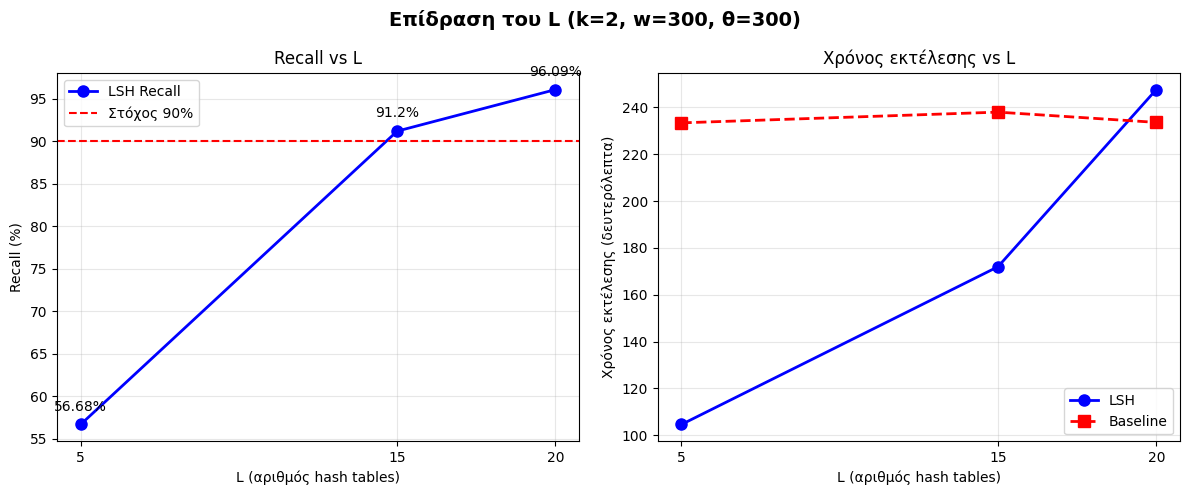

Αποθηκεύτηκε: graph1_L_effect.png


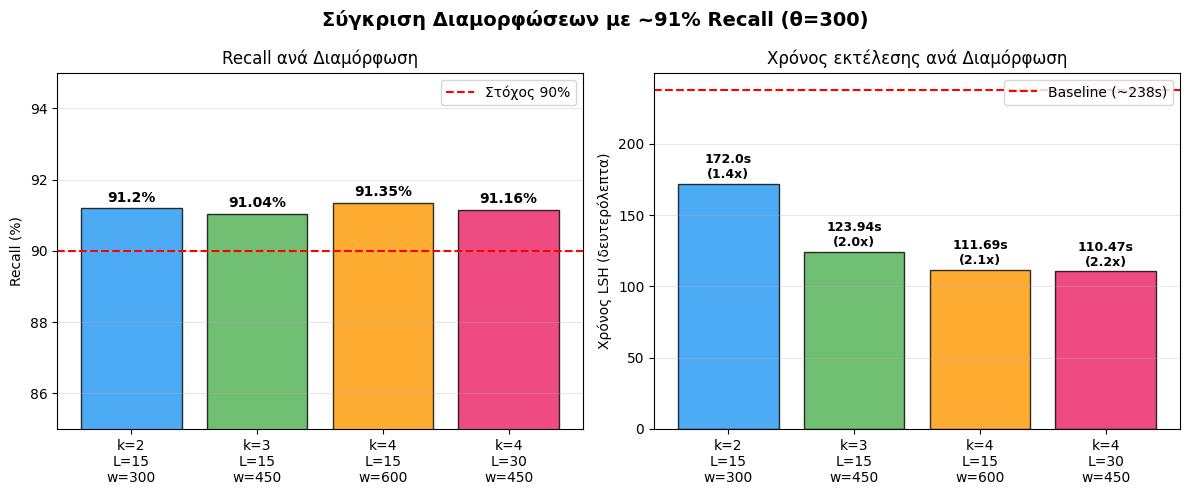

Αποθηκεύτηκε: graph2_k_comparison.png


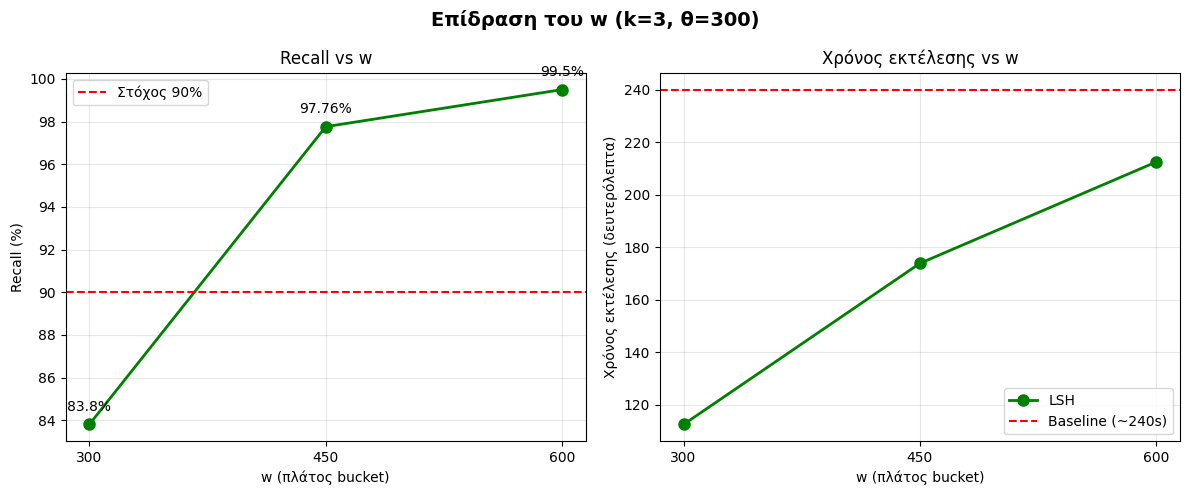

Αποθηκεύτηκε: graph3_w_effect.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

# ============================================================
# ΓΡΑΦΗΜΑ 1: Επίδραση του L στο Recall και τον Χρόνο (k=2, w=300)
# ============================================================

L_values = [5, 15, 20]
recall_k2 = [56.68, 91.20, 96.09]
time_lsh_k2 = [104.63, 172.00, 247.65]
time_baseline = [233.44, 238.02, 233.64]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Επίδραση του L (k=2, w=300, θ=300)', fontsize=14, fontweight='bold')

# Recall vs L
ax1.plot(L_values, recall_k2, 'b-o', linewidth=2, markersize=8, label='LSH Recall')
ax1.axhline(y=90, color='r', linestyle='--', label='Στόχος 90%')
ax1.set_xlabel('L (αριθμός hash tables)')
ax1.set_ylabel('Recall (%)')
ax1.set_title('Recall vs L')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_xticks(L_values)
for x, y in zip(L_values, recall_k2):
    ax1.annotate(f'{y}%', (x, y), textcoords="offset points", xytext=(0,10), ha='center')

# Χρόνος vs L
ax2.plot(L_values, time_lsh_k2, 'b-o', linewidth=2, markersize=8, label='LSH')
ax2.plot(L_values, time_baseline, 'r--s', linewidth=2, markersize=8, label='Baseline')
ax2.set_xlabel('L (αριθμός hash tables)')
ax2.set_ylabel('Χρόνος εκτέλεσης (δευτερόλεπτα)')
ax2.set_title('Χρόνος εκτέλεσης vs L')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_xticks(L_values)

plt.tight_layout()
plt.savefig('graph1_L_effect.png', dpi=150, bbox_inches='tight')
plt.show()
print("Αποθηκεύτηκε: graph1_L_effect.png")


# ============================================================
# ΓΡΑΦΗΜΑ 2: Σύγκριση k=2, k=3, k=4 (~91% recall)
# ============================================================

configs = ['k=2\nL=15\nw=300', 'k=3\nL=15\nw=450', 'k=4\nL=15\nw=600', 'k=4\nL=30\nw=450']
recall_comp = [91.20, 91.04, 91.35, 91.16]
time_comp = [172.00, 123.94, 111.69, 110.47]
speedup_comp = [1.4, 2.0, 2.1, 2.2]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Σύγκριση Διαμορφώσεων με ~91% Recall (θ=300)', fontsize=14, fontweight='bold')

colors = ['#2196F3', '#4CAF50', '#FF9800', '#E91E63']

# Recall σύγκριση
bars1 = ax1.bar(configs, recall_comp, color=colors, alpha=0.8, edgecolor='black')
ax1.axhline(y=90, color='r', linestyle='--', label='Στόχος 90%')
ax1.set_ylabel('Recall (%)')
ax1.set_title('Recall ανά Διαμόρφωση')
ax1.set_ylim(85, 95)
ax1.legend()
ax1.grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars1, recall_comp):
    ax1.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.1,
             f'{val}%', ha='center', va='bottom', fontweight='bold')

# Χρόνος και επιτάχυνση
bars2 = ax2.bar(configs, time_comp, color=colors, alpha=0.8, edgecolor='black')
ax2.axhline(y=238, color='r', linestyle='--', label=f'Baseline (~238s)')
ax2.set_ylabel('Χρόνος LSH (δευτερόλεπτα)')
ax2.set_title('Χρόνος εκτέλεσης ανά Διαμόρφωση')
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')
for bar, val, spd in zip(bars2, time_comp, speedup_comp):
    ax2.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 2,
             f'{val}s\n({spd}x)', ha='center', va='bottom', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('graph2_k_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Αποθηκεύτηκε: graph2_k_comparison.png")


# ============================================================
# ΓΡΑΦΗΜΑ 3: Επίδραση w στο Recall (k=3, L=30)
# ============================================================

w_values = [300, 450, 600]
recall_w = [83.80, 97.76, 99.50]
time_w = [112.40, 173.80, 212.44]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Επίδραση του w (k=3, θ=300)', fontsize=14, fontweight='bold')

ax1.plot(w_values, recall_w, 'g-o', linewidth=2, markersize=8)
ax1.axhline(y=90, color='r', linestyle='--', label='Στόχος 90%')
ax1.set_xlabel('w (πλάτος bucket)')
ax1.set_ylabel('Recall (%)')
ax1.set_title('Recall vs w')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_xticks(w_values)
for x, y in zip(w_values, recall_w):
    ax1.annotate(f'{y}%', (x, y), textcoords="offset points", xytext=(0,10), ha='center')

ax2.plot(w_values, time_w, 'g-o', linewidth=2, markersize=8, label='LSH')
ax2.axhline(y=240, color='r', linestyle='--', label='Baseline (~240s)')
ax2.set_xlabel('w (πλάτος bucket)')
ax2.set_ylabel('Χρόνος εκτέλεσης (δευτερόλεπτα)')
ax2.set_title('Χρόνος εκτέλεσης vs w')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_xticks(w_values)

plt.tight_layout()
plt.savefig('graph3_w_effect.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved as: graph3_w_effect.png")